# Data Analysis and Visualization - Lab 12

**Roll Number:** 24i-2551  
**Section:** DS(B)  

Hospital wait times analysis and verification notebook for Tasks 1-8 using `hospital_wait_times.csv`.

In [1]:
# import standard libraries for data analysis and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

In [2]:
# load the raw hospital dataset and preview the first rows
raw = pd.read_csv('hospital_wait_times.csv')
raw.head()

Out[2]: 
  visit_id  visit_date    site  ... treatment_minutes  satisfaction  triage_system
0  V103691  2025-08-17  Site B  ...                28           2.0            Old
1  V100198  2025-05-04  Site A  ...                75           4.0            Old
2  V104126  2025-01-17  Site A  ...                56           NaN            Old
3  V100202  2025-06-30  Site A  ...                98           3.0            Old
4  V104041  2025-08-26  Site A  ...                20           4.0            New

[5 rows x 10 columns]


,visit_id,visit_date,site,department,triage_level,age,wait_minutes,treatment_minutes,satisfaction,triage_system
0,V103691,2025-08-17,Site B,Cardiology,4,88,52.0,28,2.0,Old
1,V100198,2025-05-04,Site A,Cardiology,5,43,87.0,75,4.0,Old
2,V104126,2025-01-17,Site A,Emergency,4,31,102.0,56,NaN,Old
3,V100202,2025-06-30,Site A,Orthopedics,2,29,17.0,98,3.0,Old
4,V104041,2025-08-26,Site A,Radiology,5,68,37.0,20,4.0,New


# Task 1: Can we trust this data?

## Initial Analysis

In [3]:
# count total rows, duplicate visit ids, exact duplicates, and missing values
print('rows:', len(raw))
print('columns:', raw.shape[1])
print('extra duplicate visit_ids:', raw['visit_id'].duplicated().sum())
print('rows sharing a duplicate visit_id:', raw['visit_id'].duplicated(keep=False).sum())
print('exact duplicate rows:', raw.duplicated().sum())
print('\nmissing values per column:')
print(raw.isna().sum())

rows: 4225
columns: 10
extra duplicate visit_ids: 25
rows sharing a duplicate visit_id: 50
exact duplicate rows: 25

missing values per column:
visit_id               0
visit_date             0
site                   0
department             0
triage_level           0
age                    0
wait_minutes           0
treatment_minutes      0
satisfaction         517
triage_system          0
dtype: int64


## Your Job Analysis

In [4]:
# inspect wait_minutes for negative values, 999 placeholders, and extreme waits
neg_waits = sorted(raw.loc[raw['wait_minutes'] < 0, 'wait_minutes'].tolist())
other_long = sorted(raw.loc[(raw['wait_minutes'] > 300) & (raw['wait_minutes'] != 999), 'wait_minutes'].tolist())
print('negative waits count:', len(neg_waits), '->', neg_waits)
print('waits equal to 999:', (raw['wait_minutes'] == 999).sum())
print('other waits over 300:', len(other_long), '->', other_long)
print(raw['wait_minutes'].describe().round(2))

negative waits count: 10 -> [-57.0, -52.0, -51.0, -31.0, -20.0, -17.0, -15.0, -14.0, -10.0, -6.0]
waits equal to 999: 15
other waits over 300: 5 -> [318.0, 325.0, 339.0, 349.0, 351.0]
count    4225.00
mean       52.16
std        68.03
min       -57.00
25%        22.00
50%        39.00
75%        65.00
max       999.00
Name: wait_minutes, dtype: float64


In [5]:
# check age column for negative values, values above 120, and zeros
bad_age = (raw['age'] < 0) | (raw['age'] > 120)
print('age below 0:', (raw['age'] < 0).sum())
print('age above 120:', (raw['age'] > 120).sum())
print('age equal to 0 (newborns):', (raw['age'] == 0).sum())
print('invalid age counts:', raw.loc[bad_age, 'age'].value_counts().to_dict())

age below 0: 2
age above 120: 4
age equal to 0 (newborns): 137
invalid age counts: {230: 3, -1: 2, 150: 1}


In [6]:
# parse both date formats separately and verify the 2025 date range
iso_dates = pd.to_datetime(raw['visit_date'], format='%Y-%m-%d', errors='coerce')
dmy_dates = pd.to_datetime(raw['visit_date'], format='%d/%m/%Y', errors='coerce')
raw['date'] = iso_dates.fillna(dmy_dates)

print('yyyy-mm-dd dates:', iso_dates.notna().sum())
print('dd/mm/yyyy dates:', dmy_dates.notna().sum())
print('unparseable dates:', raw['date'].isna().sum())
print('dates outside 2025:', (raw['date'].dt.year != 2025).sum())
print('date range:', raw['date'].min().date(), 'to', raw['date'].max().date())

yyyy-mm-dd dates: 3869
dd/mm/yyyy dates: 356
unparseable dates: 0
dates outside 2025: 0
date range: 2025-01-01 to 2025-12-31


In [7]:
# examine raw department labels and standardize messy strings
print('raw department counts:')
print(raw['department'].value_counts())

raw['dept_clean'] = raw['department'].str.strip().str.title().replace({'Er': 'Emergency'})
print('\nstandardized department counts:')
print(raw['dept_clean'].value_counts())
print('raw label changes:', (raw['department'] != raw['dept_clean']).sum())

raw department counts:
department
Emergency      1204
Radiology       894
Pediatrics      767
Orthopedics     651
Cardiology      637
Emergency        27
ER               26
emergency        19
Name: count, dtype: int64

standardized department counts:
dept_clean
Emergency      1276
Radiology       894
Pediatrics      767
Orthopedics     651
Cardiology      637
Name: count, dtype: int64
raw label changes: 72


In [8]:
# check site values, triage levels, satisfaction ratings, and triage system consistency
print('site counts:', raw['site'].value_counts().to_dict())
print('triage levels:', sorted(raw['triage_level'].unique().tolist()))
print('satisfaction values:', sorted(raw['satisfaction'].dropna().unique().tolist()))
print('\ntriage_system vs site and period:')
print(pd.crosstab([raw['site'], raw['date'] >= '2025-07-01'], raw['triage_system']))

site counts: {'Site A': 2378, 'Site B': 1847}
triage levels: [1, 2, 3, 4, 5]
satisfaction values: [1.0, 2.0, 3.0, 4.0, 5.0]

triage_system vs site and period:
triage_system   New   Old
site   date              
Site A False      0  1185
       True    1193     0
Site B False      0   935
       True       0   912


In [9]:
# build the valid cohort by removing exact duplicates, invalid ages, and sentinel waits
dedup = raw.drop_duplicates().copy()
print('unique visit_ids after drop_duplicates:', dedup['visit_id'].is_unique)
print('unique cohort department changes:', (dedup['department'] != dedup['dept_clean']).sum())

valid_mask = (
    (dedup['date'].dt.year == 2025)
    & dedup['age'].between(0, 120)
    & (dedup['wait_minutes'] >= 0)
    & (dedup['wait_minutes'] != 999)
)
valid = dedup.loc[valid_mask].copy()
print('valid cohort department changes:', (valid['department'] != valid['dept_clean']).sum())
valid['department'] = valid['dept_clean']
print('rows in raw:', len(raw), '| valid rows:', len(valid))

unique visit_ids after drop_duplicates: True
unique cohort department changes: 70
valid cohort department changes: 69
rows in raw: 4225 | valid rows: 4169


# Task 2: Did the new triage system work?

## Initial Analysis

In [10]:
# label pre and post periods around july 1, 2025 and add a month column
cutoff = pd.Timestamp('2025-07-01')
valid['period'] = 'before'
valid.loc[valid['date'] >= cutoff, 'period'] = 'after'
valid['month'] = valid['date'].dt.to_period('M').dt.to_timestamp()

# compute site a mean wait and counts before and after july 1
site_a = valid[valid['site'] == 'Site A']
site_a_stats = site_a.groupby('period')['wait_minutes'].agg(['count', 'mean']).reindex(['before', 'after'])
print(site_a_stats.round(2))
a_change = site_a_stats.loc['after', 'mean'] - site_a_stats.loc['before', 'mean']
print('site a change (after - before):', round(a_change, 2))

        count   mean
period              
before   1169  54.98
after    1175  40.86
site a change (after - before): -14.12


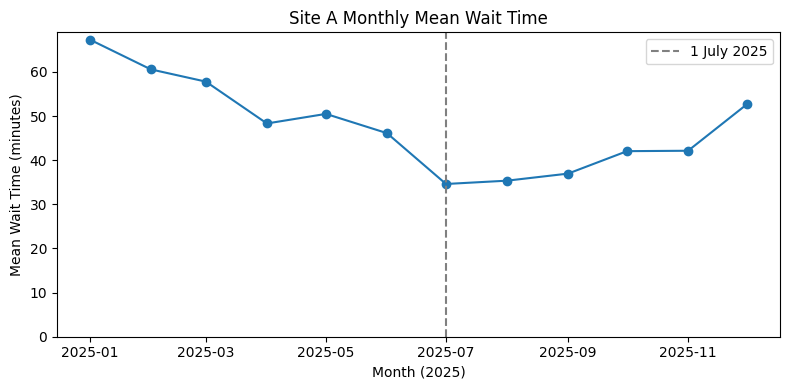

In [11]:
# plot basic monthly mean line chart for site a
a_monthly = site_a.groupby('month')['wait_minutes'].mean()
plt.figure(figsize=(8, 4))
plt.plot(a_monthly.index, a_monthly.values, marker='o')
plt.axvline(cutoff, color='gray', linestyle='--', label='1 July 2025')
plt.xlabel('Month (2025)')
plt.ylabel('Mean Wait Time (minutes)')
plt.title('Site A Monthly Mean Wait Time')
plt.ylim(bottom=0)
plt.legend()
plt.tight_layout()
plt.show()

## Your Job Analysis

In [12]:
# compare monthly mean waits for site a and site b across all of 2025
monthly_sites = valid.groupby(['month', 'site'])['wait_minutes'].mean().unstack()
monthly_sites['Gap (A - B)'] = monthly_sites['Site A'] - monthly_sites['Site B']
monthly_print = monthly_sites.copy()
monthly_print.index = monthly_print.index.strftime('%b')
print(monthly_print.round(2))

site   Site A  Site B  Gap (A - B)
month                             
Jan     67.32   66.14         1.18
Feb     60.57   63.88        -3.31
Mar     57.79   53.88         3.91
Apr     48.31   54.06        -5.75
May     50.48   47.65         2.83
Jun     46.12   39.79         6.33
Jul     34.60   37.92        -3.32
Aug     35.35   38.19        -2.84
Sep     36.95   43.02        -6.07
Oct     42.04   46.99        -4.95
Nov     42.13   49.21        -7.08
Dec     52.70   60.50        -7.80


In [13]:
# compute site b changes and the difference-in-differences estimate
site_b = valid[valid['site'] == 'Site B']
site_b_stats = site_b.groupby('period')['wait_minutes'].agg(['count', 'mean']).reindex(['before', 'after'])
print('site b stats:')
print(site_b_stats.round(2))

b_change = site_b_stats.loc['after', 'mean'] - site_b_stats.loc['before', 'mean']
did = a_change - b_change
print('\nsite a change:', round(a_change, 4))
print('site b change:', round(b_change, 4))
print('difference-in-differences (a - b):', round(did, 4))

site b stats:
        count   mean
period              
before    920  54.09
after     905  46.28

site a change: -14.1174
site b change: -7.8172
difference-in-differences (a - b): -6.3001


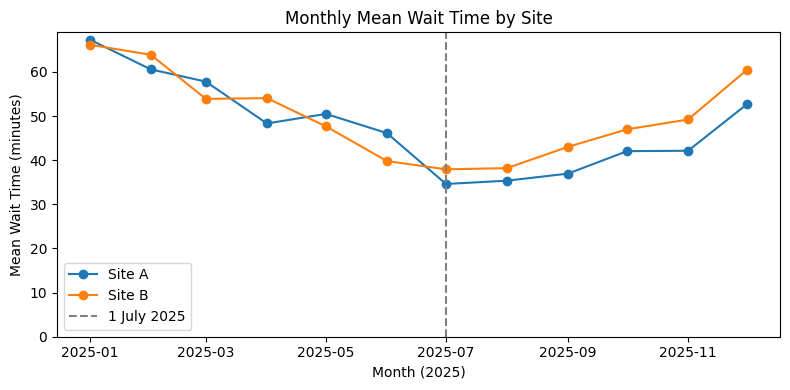

In [14]:
# plot monthly mean wait times for both sites on one basic chart
plt.figure(figsize=(8, 4))
plt.plot(monthly_sites.index, monthly_sites['Site A'], marker='o', label='Site A')
plt.plot(monthly_sites.index, monthly_sites['Site B'], marker='o', label='Site B')
plt.axvline(cutoff, color='gray', linestyle='--', label='1 July 2025')
plt.xlabel('Month (2025)')
plt.ylabel('Mean Wait Time (minutes)')
plt.title('Monthly Mean Wait Time by Site')
plt.ylim(bottom=0)
plt.legend()
plt.tight_layout()
plt.show()

# Task 3: Which departments improved?

## Initial Analysis

In [15]:
# summarize standardized department changes and compute before vs after mean waits
print('rows changed (raw / unique / valid):',
      (raw['department'] != raw['dept_clean']).sum(),
      (dedup['department'] != dedup['dept_clean']).sum(),
      (dedup.loc[valid_mask, 'department'] != valid['department']).sum())

dept_means = valid.groupby(['department', 'period'])['wait_minutes'].mean().unstack()[['before', 'after']]
dept_means['change'] = dept_means['after'] - dept_means['before']
print('\ndepartment mean waits (both sites combined):')
print(dept_means.round(2))

rows changed (raw / unique / valid): 72 70 69

department mean waits (both sites combined):
period       before  after  change
department                        
Cardiology    51.66  45.57   -6.09
Emergency     73.46  63.16  -10.29
Orthopedics   61.82  51.17  -10.65
Pediatrics    41.80  35.63   -6.17
Radiology     26.64  21.72   -4.92


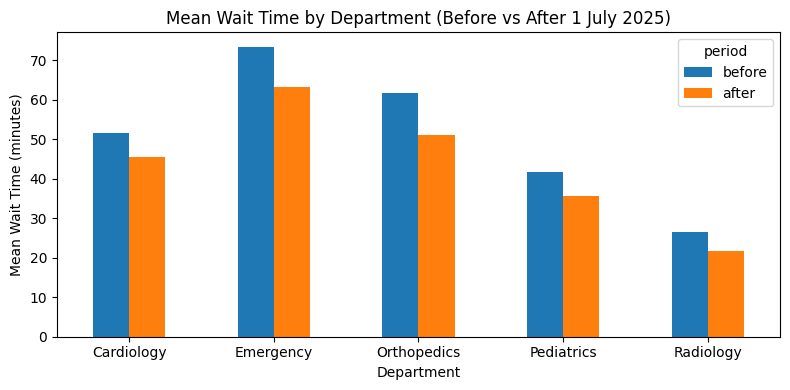

In [16]:
# plot basic grouped bar chart of department waits before vs after july 1
dept_means[['before', 'after']].plot(kind='bar', figsize=(8, 4))
plt.xlabel('Department')
plt.ylabel('Mean Wait Time (minutes)')
plt.title('Mean Wait Time by Department (Before vs After 1 July 2025)')
plt.xticks(rotation=0)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

## Your Job Analysis

In [17]:
# compute overall pooled change and department visit shares before and after july 1
overall = valid.groupby('period')['wait_minutes'].mean().reindex(['before', 'after'])
raw_change = overall['after'] - overall['before']
print('overall pooled means:', overall.round(4).to_dict())
print('raw overall change:', round(raw_change, 4))

dept_counts = valid.groupby(['department', 'period']).size().unstack()[['before', 'after']]
dept_shares = dept_counts.div(dept_counts.sum()) * 100
dept_shares['share_change_pp'] = dept_shares['after'] - dept_shares['before']
print('\ndepartment counts:')
print(dept_counts)
print('\ndepartment percentage shares:')
print(dept_shares.round(2))

overall pooled means: {'before': 54.5907, 'after': 43.2192}
raw overall change: -11.3715

department counts:
period       before  after
department                
Cardiology      320    310
Emergency       676    582
Orthopedics     365    277
Pediatrics      389    363
Radiology       339    548

department percentage shares:
period       before  after  share_change_pp
department                                 
Cardiology    15.32  14.90            -0.41
Emergency     32.36  27.98            -4.38
Orthopedics   17.47  13.32            -4.16
Pediatrics    18.62  17.45            -1.17
Radiology     16.23  26.35            10.12


In [18]:
# recompute post mean holding pre-july department mix weights constant
pre_weights = dept_shares['before'] / 100.0
fixed_mix_post = (pre_weights * dept_means['after']).sum()
within_change = fixed_mix_post - overall['before']
mix_effect = overall['after'] - fixed_mix_post

print('fixed-mix post mean:', round(fixed_mix_post, 4))
print('within-department change (constant mix):', round(within_change, 4))
print('mix-shift effect:', round(mix_effect, 4))
print('share of overall decline due to mix (%):', round(100 * mix_effect / raw_change, 2))

fixed-mix post mean: 46.5196
within-department change (constant mix): -8.0711
mix-shift effect: -3.3004
share of overall decline due to mix (%): 29.02


# Task 4: Does waiting reduce satisfaction?

## Initial Analysis

In [19]:
# compare respondent mean satisfaction and counts for <= 90 and > 90 minutes without imputation
raw['wait_group'] = '<= 90'
raw.loc[raw['wait_minutes'] > 90, 'wait_group'] = '> 90'
valid['wait_group'] = '<= 90'
valid.loc[valid['wait_minutes'] > 90, 'wait_group'] = '> 90'

print('raw rows summary:')
print(raw.groupby('wait_group')['satisfaction'].agg(['count', 'mean']).round(3))
print('raw overall respondent mean:', round(raw['satisfaction'].mean(), 4))
print('raw correlation (wait vs satisfaction):', round(raw['wait_minutes'].corr(raw['satisfaction']), 4))

print('\nvalid rows summary:')
print(valid.groupby('wait_group')['satisfaction'].agg(['count', 'mean']).round(3))
print('valid overall respondent mean:', round(valid['satisfaction'].mean(), 4))
print('valid correlation (wait vs satisfaction):', round(valid['wait_minutes'].corr(valid['satisfaction']), 4))

raw rows summary:
            count   mean
wait_group              
<= 90        3409  3.648
> 90          299  2.314
raw overall respondent mean: 3.5405
raw correlation (wait vs satisfaction): -0.3086

valid rows summary:
            count   mean
wait_group              
<= 90        3375  3.649
> 90          283  2.279
valid overall respondent mean: 3.5432
valid correlation (wait vs satisfaction): -0.5572


## Your Job Analysis

In [20]:
# compute missing satisfaction counts and percentages in both wait groups
raw_miss = raw.groupby('wait_group')['satisfaction'].agg(total='size', rated='count')
raw_miss['missing'] = raw_miss['total'] - raw_miss['rated']
raw_miss['missing_pct'] = 100 * raw_miss['missing'] / raw_miss['total']
print('raw missingness:')
print(raw_miss.round(2))

valid_miss = valid.groupby('wait_group')['satisfaction'].agg(total='size', rated='count', mean='mean')
valid_miss['missing'] = valid_miss['total'] - valid_miss['rated']
valid_miss['missing_pct'] = 100 * valid_miss['missing'] / valid_miss['total']
print('\nvalid missingness:')
print(valid_miss.round(2))

raw missingness:
            total  rated  missing  missing_pct
wait_group                                    
<= 90        3700   3409      291         7.86
> 90          525    299      226        43.05

valid missingness:
            total  rated  mean  missing  missing_pct
wait_group                                          
<= 90        3664   3375  3.65      289         7.89
> 90          505    283  2.28      222        43.96


In [21]:
# check missing satisfaction percentages by department and triage level
print('missing satisfaction % by department:')
print((valid['satisfaction'].isna().groupby(valid['department']).mean() * 100).round(2))
print('\nmissing satisfaction % by triage level:')
print((valid['satisfaction'].isna().groupby(valid['triage_level']).mean() * 100).round(2))

# compute sensitivity estimate and 1-5 scale bounds for all valid visits
weighted_est = (valid_miss['mean'] * valid_miss['total']).sum() / valid_miss['total'].sum()
miss_n = valid['satisfaction'].isna().sum()
score_sum = valid['satisfaction'].sum()
low_bound = (score_sum + 1.0 * miss_n) / len(valid)
high_bound = (score_sum + 5.0 * miss_n) / len(valid)
print('\nreweighted mean assuming missing matches wait band:', round(weighted_est, 4))
print('all-visit 1-5 scale bounds:', round(low_bound, 4), 'to', round(high_bound, 4))

missing satisfaction % by department:
department
Cardiology     10.63
Emergency      16.93
Orthopedics    12.77
Pediatrics      9.71
Radiology       8.57
Name: satisfaction, dtype: float64

missing satisfaction % by triage level:
triage_level
1    12.43
2     6.89
3    10.76
4    14.51
5    18.32
Name: satisfaction, dtype: float64

reweighted mean assuming missing matches wait band: 3.4832
all-visit 1-5 scale bounds: 3.2315 to 3.7218


# Task 5: The board headline

## Initial Analysis

board headline (association language):
average waits declined at both sites during the second half of 2025.
the reduction was larger at site a, coinciding with the july 1 triage transition.


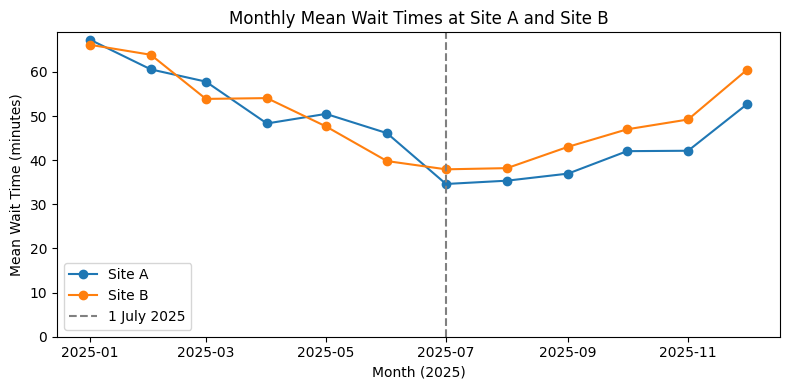

In [22]:
# plot monthly mean waits for both sites with a vertical marker at july 1, 2025
plt.figure(figsize=(8, 4))
plt.plot(monthly_sites.index, monthly_sites['Site A'], marker='o', label='Site A')
plt.plot(monthly_sites.index, monthly_sites['Site B'], marker='o', label='Site B')
plt.axvline(cutoff, color='gray', linestyle='--', label='1 July 2025')
plt.xlabel('Month (2025)')
plt.ylabel('Mean Wait Time (minutes)')
plt.title('Monthly Mean Wait Times at Site A and Site B')
plt.ylim(bottom=0)
plt.legend()
plt.tight_layout()
plt.show()

print('board headline (association language):')
print('average waits declined at both sites during the second half of 2025.')
print('the reduction was larger at site a, coinciding with the july 1 triage transition.')

## Your Job Analysis

In [23]:
# compute overall mean, median, and 90th percentile wait times for valid visits
print('overall mean:', round(valid['wait_minutes'].mean(), 2))
print('overall median:', valid['wait_minutes'].median())
print('overall 90th percentile:', valid['wait_minutes'].quantile(0.90))

print('\nsummary by period:')
period_summary = valid.groupby('period')['wait_minutes'].agg(
    mean='mean',
    median='median',
    p90=lambda s: s.quantile(0.90)
).reindex(['before', 'after'])
print(period_summary.round(2))

print('\nsummary by site and period:')
site_period_summary = valid.groupby(['site', 'period'])['wait_minutes'].agg(
    mean='mean',
    median='median',
    p90=lambda s: s.quantile(0.90)
).unstack(0)
print(site_period_summary.round(2))

overall mean: 48.92
overall median: 39.0
overall 90th percentile: 98.0

summary by period:
         mean  median    p90
period                      
before  54.59    44.0  110.0
after   43.22    34.0   85.0

summary by site and period:
         mean        median           p90       
site   Site A Site B Site A Site B Site A Site B
period                                          
after   40.86  46.28   32.0   37.0   82.0   88.0
before  54.98  54.09   45.0   43.5  109.0  111.1


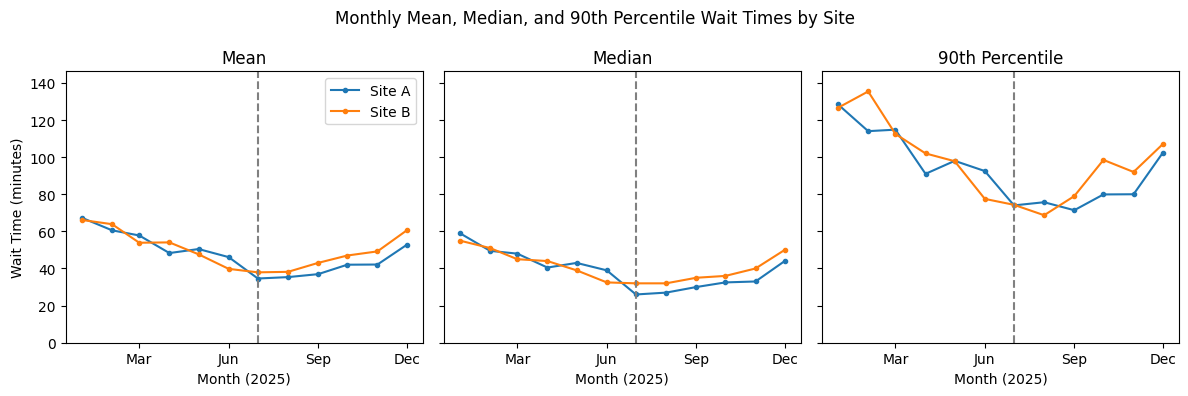

In [24]:
# plot a 3-panel chart comparing monthly mean, median, and 90th percentile by site
m_mean = valid.groupby(['month', 'site'])['wait_minutes'].mean().unstack()
m_med = valid.groupby(['month', 'site'])['wait_minutes'].median().unstack()
m_p90 = valid.groupby(['month', 'site'])['wait_minutes'].quantile(0.90).unstack()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
y_top = max(m_mean.to_numpy().max(), m_med.to_numpy().max(), m_p90.to_numpy().max()) * 1.08
panels = [(m_mean, 'Mean'), (m_med, 'Median'), (m_p90, '90th Percentile')]
for ax, (tbl, title) in zip(axes, panels):
    ax.plot(tbl.index, tbl['Site A'], marker='o', markersize=3, label='Site A')
    ax.plot(tbl.index, tbl['Site B'], marker='o', markersize=3, label='Site B')
    ax.axvline(cutoff, color='gray', linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('Month (2025)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax.set_ylim(0, y_top)

axes[0].set_ylabel('Wait Time (minutes)')
axes[0].legend()
fig.suptitle('Monthly Mean, Median, and 90th Percentile Wait Times by Site')
plt.tight_layout()
plt.show()

# Task 6: Do older patients wait longer?

## Initial Analysis

In [25]:
# compute correlation between age and wait_minutes and summarize across age bins
print('correlation age vs wait_minutes:', round(valid['age'].corr(valid['wait_minutes']), 4))

valid['age_group'] = pd.cut(valid['age'], bins=[-1, 17, 39, 64, 120], labels=['0-17', '18-39', '40-64', '65+'])
age_stats = valid.groupby('age_group', observed=True)['wait_minutes'].agg(['count', 'mean', 'median'])
print(age_stats.round(2))

correlation age vs wait_minutes: 0.0051
           count   mean  median
age_group                      
0-17         573  48.80    38.0
18-39       1340  47.91    39.0
40-64       1623  49.38    39.0
65+          633  49.97    40.0


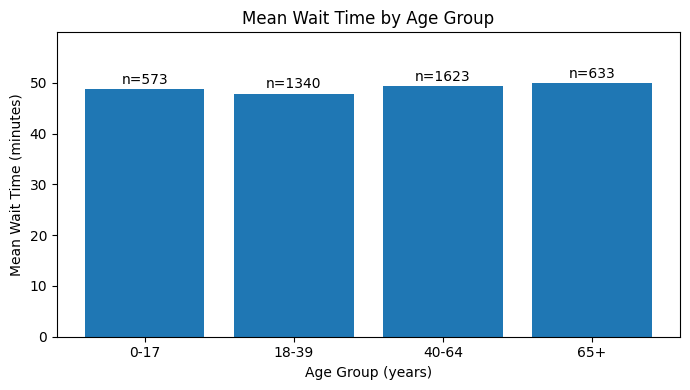

In [26]:
# plot basic bar chart of mean wait time by age group
plt.figure(figsize=(7, 4))
bars = plt.bar(age_stats.index.astype(str), age_stats['mean'])
for bar, n in zip(bars, age_stats['count']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f'n={n}', ha='center')
plt.xlabel('Age Group (years)')
plt.ylabel('Mean Wait Time (minutes)')
plt.title('Mean Wait Time by Age Group')
plt.ylim(0, age_stats['mean'].max() * 1.2)
plt.tight_layout()
plt.show()

## Your Job Analysis

In [27]:
# compute wait times and age distributions by triage level to check for confounding
triage_stats = valid.groupby('triage_level').agg(
    count=('wait_minutes', 'size'),
    mean_wait=('wait_minutes', 'mean'),
    median_wait=('wait_minutes', 'median'),
    mean_age=('age', 'mean'),
    median_age=('age', 'median')
)
print(triage_stats.round(2))

print('\nage vs wait correlation within each triage level:')
for lvl, grp in valid.groupby('triage_level'):
    print('triage', lvl, 'r:', round(grp['age'].corr(grp['wait_minutes']), 4))

print('\npercentage of each age group across triage levels:')
print((pd.crosstab(valid['age_group'], valid['triage_level'], normalize='index') * 100).round(1))

              count  mean_wait  median_wait  mean_age  median_age
triage_level                                                     
1               169       8.94          8.0     42.40        41.0
2               639      22.30         19.0     41.72        42.0
3              1654      45.40         38.0     41.64        41.0
4              1172      63.29         54.0     41.91        42.0
5               535      72.73         62.0     43.18        44.0

age vs wait correlation within each triage level:
triage 1 r: 0.0229
triage 2 r: -0.0847
triage 3 r: -0.0214
triage 4 r: 0.0177
triage 5 r: 0.0357

percentage of each age group across triage levels:
triage_level    1     2     3     4     5
age_group                                
0-17          3.8  16.2  38.2  29.0  12.7
18-39         4.3  15.1  42.1  27.2  11.3
40-64         3.8  15.7  38.6  28.7  13.2
65+           4.6  14.1  38.5  27.6  15.2


# Task 7: Should we remove the outliers?

## Initial Analysis

In [28]:
# identify iqr outliers in wait_minutes and compare mean waits with and without them
q1 = valid['wait_minutes'].quantile(0.25)
q3 = valid['wait_minutes'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

is_outlier = (valid['wait_minutes'] < lower) | (valid['wait_minutes'] > upper)
outliers = valid[is_outlier]
no_outliers = valid[~is_outlier]

print('q1:', q1, '| q3:', q3, '| iqr:', iqr)
print('lower fence:', lower, '| upper fence:', upper)
print('iqr outlier count:', len(outliers))
print('mean wait with outliers:', round(valid['wait_minutes'].mean(), 2))
print('mean wait without outliers:', round(no_outliers['wait_minutes'].mean(), 2))

q1: 22.0 | q3: 64.0 | iqr: 42.0
lower fence: -41.0 | upper fence: 127.0
iqr outlier count: 183
mean wait with outliers: 48.92
mean wait without outliers: 43.65


## Your Job Analysis

In [29]:
# inspect outlier counts by department and triage level
print('outliers by department:')
print(outliers['department'].value_counts())
print('\noutliers by triage level:')
print(outliers['triage_level'].value_counts().sort_index())

print('\ndepartment x triage_level crosstab of outliers:')
ct = pd.crosstab(outliers['department'], outliers['triage_level'])
ct = ct.reindex(index=sorted(valid['department'].unique()), columns=[1, 2, 3, 4, 5], fill_value=0)
ct['Total'] = ct.sum(axis=1)
print(ct)

outliers by department:
department
Emergency      127
Orthopedics     35
Cardiology      15
Pediatrics       6
Name: count, dtype: int64

outliers by triage level:
triage_level
3    35
4    89
5    59
Name: count, dtype: int64

department x triage_level crosstab of outliers:
triage_level  1  2   3   4   5  Total
department                           
Cardiology    0  0   1   8   6     15
Emergency     0  0  26  65  36    127
Orthopedics   0  0   7  14  14     35
Pediatrics    0  0   1   2   3      6
Radiology     0  0   0   0   0      0


skewness (valid): 1.93
max wait (valid): 351.0 | max wait (raw): 999.0
visits > 180 min (valid): 38 | (raw): 53


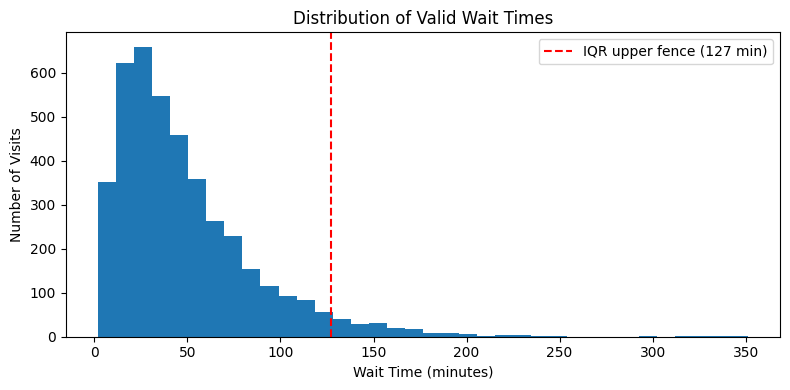

In [30]:
# check skewness, maximum wait, and visits over 180 minutes
print('skewness (valid):', round(valid['wait_minutes'].skew(), 2))
print('max wait (valid):', valid['wait_minutes'].max(), '| max wait (raw):', raw['wait_minutes'].max())
print('visits > 180 min (valid):', (valid['wait_minutes'] > 180).sum(),
      '| (raw):', (raw['wait_minutes'] > 180).sum())

# plot histogram of wait_minutes with iqr upper fence
plt.figure(figsize=(8, 4))
plt.hist(valid['wait_minutes'], bins=36)
plt.axvline(upper, color='red', linestyle='--', label=f'IQR upper fence ({upper:.0f} min)')
plt.xlabel('Wait Time (minutes)')
plt.ylabel('Number of Visits')
plt.title('Distribution of Valid Wait Times')
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
# check whether removing outliers changes the site a vs site b difference-in-differences
trim_means = no_outliers.groupby(['site', 'period'])['wait_minutes'].mean().unstack()[['before', 'after']]
trim_a_change = trim_means.loc['Site A', 'after'] - trim_means.loc['Site A', 'before']
trim_b_change = trim_means.loc['Site B', 'after'] - trim_means.loc['Site B', 'before']
trim_did = trim_a_change - trim_b_change

print('without outliers -> site a change:', round(trim_a_change, 2),
      '| site b change:', round(trim_b_change, 2),
      '| did:', round(trim_did, 2))
print('with outliers    -> site a change:', round(a_change, 2),
      '| site b change:', round(b_change, 2),
      '| did:', round(did, 2))

without outliers -> site a change: -10.43 | site b change: -4.69 | did: -5.74
with outliers    -> site a change: -14.12 | site b change: -7.82 | did: -6.3


# Task 8: Is the improvement statistically real?

## Initial Analysis

In [32]:
# run welch t-test for site a before vs after july 1 and report p-values and 95% ci
a_pre = valid.loc[(valid['site'] == 'Site A') & (valid['period'] == 'before'), 'wait_minutes']
a_post = valid.loc[(valid['site'] == 'Site A') & (valid['period'] == 'after'), 'wait_minutes']

res_a_two = stats.ttest_ind(a_post, a_pre, equal_var=False)
res_a_one = stats.ttest_ind(a_post, a_pre, equal_var=False, alternative='less')
ci_a = res_a_two.confidence_interval(0.95)

print('site a change (after - before):', round(a_post.mean() - a_pre.mean(), 2))
print('site a one-sided p-value:', res_a_one.pvalue)
print('site a two-sided p-value:', res_a_two.pvalue)
print('site a 95% ci (after - before):', round(ci_a.low, 2), 'to', round(ci_a.high, 2))

site a change (after - before): -14.12
site a one-sided p-value: 7.71102639698813e-21
site a two-sided p-value: 1.542205279397626e-20
site a 95% ci (after - before): -17.07 to -11.17


## Your Job Analysis

In [33]:
# run the same welch t-test for site b before vs after july 1
b_pre = valid.loc[(valid['site'] == 'Site B') & (valid['period'] == 'before'), 'wait_minutes']
b_post = valid.loc[(valid['site'] == 'Site B') & (valid['period'] == 'after'), 'wait_minutes']

res_b_two = stats.ttest_ind(b_post, b_pre, equal_var=False)
res_b_one = stats.ttest_ind(b_post, b_pre, equal_var=False, alternative='less')
ci_b = res_b_two.confidence_interval(0.95)

print('site b change (after - before):', round(b_post.mean() - b_pre.mean(), 2))
print('site b one-sided p-value:', res_b_one.pvalue)
print('site b two-sided p-value:', res_b_two.pvalue)
print('site b 95% ci (after - before):', round(ci_b.low, 2), 'to', round(ci_b.high, 2))

site b change (after - before): -7.82
site b one-sided p-value: 7.0463683807179215e-06
site b two-sided p-value: 1.4092736761435843e-05
site b 95% ci (after - before): -11.34 to -4.3


In [34]:
# compute a stratified visit bootstrap 95% confidence interval for the unadjusted did
rng = np.random.default_rng(2025)
boot_dids = []
a_pre_arr = a_pre.to_numpy()
a_post_arr = a_post.to_numpy()
b_pre_arr = b_pre.to_numpy()
b_post_arr = b_post.to_numpy()

for _ in range(10000):
    m_apre = rng.choice(a_pre_arr, size=len(a_pre_arr), replace=True).mean()
    m_apost = rng.choice(a_post_arr, size=len(a_post_arr), replace=True).mean()
    m_bpre = rng.choice(b_pre_arr, size=len(b_pre_arr), replace=True).mean()
    m_bpost = rng.choice(b_post_arr, size=len(b_post_arr), replace=True).mean()
    boot_dids.append((m_apost - m_apre) - (m_bpost - m_bpre))

boot_ci = np.quantile(boot_dids, [0.025, 0.975])
print('unadjusted did:', round(did, 4))
print('bootstrap 95% ci:', round(boot_ci[0], 2), 'to', round(boot_ci[1], 2))

unadjusted did: -6.3001
bootstrap 95% ci: -10.98 to -1.71


In [35]:
# compare urgent patient shares (triage levels 1-2) and fit an adjusted ols did model
valid['urgent'] = valid['triage_level'].isin([1, 2])
urgent_tbl = valid.groupby(['site', 'period'])['urgent'].agg(['sum', 'size', 'mean'])
urgent_tbl['pct'] = urgent_tbl['mean'] * 100
print('urgent counts and shares:')
print(urgent_tbl.round(2))
print('\nmean wait by urgent status:')
print(valid.groupby('urgent')['wait_minutes'].mean().round(2))

# fit ols with site, period, interaction, and department + triage dummies
site_a_flag = (valid['site'] == 'Site A').astype(float)
post_flag = (valid['period'] == 'after').astype(float)
dummies = pd.get_dummies(valid[['department', 'triage_level']], columns=['department', 'triage_level'], drop_first=True, dtype=float)
X = np.column_stack([np.ones(len(valid)), site_a_flag, post_flag, site_a_flag * post_flag, dummies])
y = valid['wait_minutes'].to_numpy()
coefs, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
adj_did = coefs[3]
print('\nadjusted did (controlling for department and triage_level):', round(adj_did, 4))
print('difference (adjusted - unadjusted):', round(adj_did - did, 4))

urgent counts and shares:
               sum  size  mean    pct
site   period                        
Site A after   255  1175  0.22  21.70
       before  219  1169  0.19  18.73
Site B after   143   905  0.16  15.80
       before  191   920  0.21  20.76

mean wait by urgent status:
urgent
False    55.99
True     19.50
Name: wait_minutes, dtype: float64

adjusted did (controlling for department and triage_level): -4.0746
difference (adjusted - unadjusted): 2.2255


# Summary

In [36]:
# print a concise final summary of key verified findings
print('roll number: 24i-2551 | section: ds(b)')
print('valid visits:', len(valid), '(from', len(raw), 'raw rows)')
print('site a change:', round(a_change, 2), '| site b change:', round(b_change, 2),
      '| unadjusted did:', round(did, 2), '| adjusted did:', round(adj_did, 2))
print('overall change:', round(raw_change, 2), '| constant-mix change:', round(within_change, 2),
      '| mix share:', round(100 * mix_effect / raw_change, 1), '%')
print('missing satisfaction % (<=90 vs >90):', round(valid_miss.loc['<= 90', 'missing_pct'], 2),
      'vs', round(valid_miss.loc['> 90', 'missing_pct'], 2))
print('overall mean / median / p90 wait:', round(valid['wait_minutes'].mean(), 2),
      '/', valid['wait_minutes'].median(), '/', valid['wait_minutes'].quantile(0.90))
print('iqr outliers:', len(outliers), '| visits > 180 min:', (valid['wait_minutes'] > 180).sum())
print('site a one-sided p:', res_a_one.pvalue, '| site b one-sided p:', res_b_one.pvalue)

roll number: 24i-2551 | section: ds(b)
valid visits: 4169 (from 4225 raw rows)
site a change: -14.12 | site b change: -7.82 | unadjusted did: -6.3 | adjusted did: -4.07
overall change: -11.37 | constant-mix change: -8.07 | mix share: 29.0 %
missing satisfaction % (<=90 vs >90): 7.89 vs 43.96
overall mean / median / p90 wait: 48.92 / 39.0 / 98.0
iqr outliers: 183 | visits > 180 min: 38
site a one-sided p: 7.71102639698813e-21 | site b one-sided p: 7.0463683807179215e-06
